In [1]:
# libraries
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# data
df_train = pd.read_csv('../data/train_orders.csv')
df_train.tail()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
3214869,2558525,206209,prior,9,4,15,22.0
3214870,2266710,206209,prior,10,5,18,29.0
3214871,1854736,206209,prior,11,4,10,30.0
3214872,626363,206209,prior,12,1,12,18.0
3214873,2977660,206209,prior,13,1,12,7.0


## Create baseline model
-- Use median by user

In [3]:
df_train_full = df_train.copy()

# df_val = df_train_full.groupby('user_id').tail(1)
df_val = df_train_full.groupby('user_id').tail(1).copy()

df_train = df_train_full.drop(df_val.index)

df_train

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0
...,...,...,...,...,...,...,...
3214868,2129269,206209,prior,8,3,17,22.0
3214869,2558525,206209,prior,9,4,15,22.0
3214870,2266710,206209,prior,10,5,18,29.0
3214871,1854736,206209,prior,11,4,10,30.0


In [4]:
# create binary target observed
df_val['binary_target_observed'] = df_val['days_since_prior_order'] <= 7
df_val

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,binary_target_observed
9,2550362,1,prior,10,4,8,30.0,False
23,839880,2,prior,14,3,10,13.0,False
35,1402502,3,prior,12,1,15,15.0,False
40,2557754,4,prior,5,5,13,0.0,True
44,157374,5,prior,4,1,18,19.0,False
...,...,...,...,...,...,...,...,...
3214728,414137,206205,prior,3,5,16,10.0,False
3214795,1904200,206206,prior,67,0,13,11.0,False
3214811,1005822,206207,prior,16,2,7,18.0,False
3214860,1882108,206208,prior,49,1,22,7.0,True


In [5]:
# get median baseline prediction
median_baseline = df_train.groupby('user_id')['days_since_prior_order'].median().reset_index().rename(
    columns={'days_since_prior_order':'median_baseline_pred'}
)

median_baseline

,user_id,median_baseline_pred
0,1,19.5
1,2,11.5
2,3,10.0
3,4,19.0
4,5,10.5
...,...,...
206204,206205,30.0
206205,206206,3.0
206206,206207,8.0
206207,206208,7.0


In [6]:
# Next: attach median baseline prediction to validation set and score it.
df_val = df_val.merge(median_baseline, on='user_id', how='left')
df_val.head()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,binary_target_observed,median_baseline_pred
0,2550362,1,prior,10,4,8,30.0,False,19.5
1,839880,2,prior,14,3,10,13.0,False,11.5
2,1402502,3,prior,12,1,15,15.0,False,10.0
3,2557754,4,prior,5,5,13,0.0,True,19.0
4,157374,5,prior,4,1,18,19.0,False,10.5


In [7]:
# convert median baseline prediction into a binary variable
df_val['binary_baseline_pred'] = df_val['median_baseline_pred'] <= 7.0
df_val

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,binary_target_observed,median_baseline_pred,binary_baseline_pred
0,2550362,1,prior,10,4,8,30.0,False,19.5,False
1,839880,2,prior,14,3,10,13.0,False,11.5,False
2,1402502,3,prior,12,1,15,15.0,False,10.0,False
3,2557754,4,prior,5,5,13,0.0,True,19.0,False
4,157374,5,prior,4,1,18,19.0,False,10.5,False
...,...,...,...,...,...,...,...,...,...,...
206204,414137,206205,prior,3,5,16,10.0,False,30.0,False
206205,1904200,206206,prior,67,0,13,11.0,False,3.0,True
206206,1005822,206207,prior,16,2,7,18.0,False,8.0,False
206207,1882108,206208,prior,49,1,22,7.0,True,7.0,True


In [8]:
# score the variable
sum(df_val['binary_target_observed'] == df_val['binary_baseline_pred']) / len(df_val)

0.7282174880824794

### Logistic Regression Model

In [9]:
df_train.head()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


In [10]:
# import logistic regression
from sklearn.linear_model import LogisticRegression

In [11]:
# create binary target
df_train['days_since_prior_order_diff'] = df_train.groupby('user_id')['days_since_prior_order'].shift(-1)

In [12]:
# Remove rows with no diff
df_train = df_train[~df_train['days_since_prior_order_diff'].isna()].copy()

In [13]:
# Create binary target
df_train['binary_target_observed'] = df_train['days_since_prior_order_diff'] <= 7
df_train.head()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,days_since_prior_order_diff,binary_target_observed
0,2539329,1,prior,1,2,8,NaN,15.0,False
1,2398795,1,prior,2,3,7,15.0,21.0,False
2,473747,1,prior,3,3,12,21.0,29.0,False
3,2254736,1,prior,4,4,7,29.0,28.0,False
4,431534,1,prior,5,4,15,28.0,19.0,False


In [14]:
# Select features
# features = ['order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']

In [15]:
# Handle missing features (there are none)

In [16]:
# Encode features where necessary
# pd.get_dummies(df_train['order_dow'], prefix='order_dow', drop_first=True, dtype=int)

In [17]:
# Select handle missing features and encode
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_features = ['order_number', 'days_since_prior_order']
categorical_features = ['order_dow', 'order_hour_of_day']

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), numeric_features),

    ('categorical', OneHotEncoder(
        drop='first',
        handle_unknown='ignore'
    ), categorical_features)
])

In [18]:
# Prepare training set
X_train = df_train[
    ['order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']
]

y_train = df_train['binary_target_observed']

In [19]:
# Fit logistic regression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('preprocessor', preprocessor),
    ('logistic_regression', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['order_number',
                                                   'days_since_prior_order']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['order_dow',
                                                   'order_hour_of_day'])])),
                ('logistic_regression', LogisticRegression(max_iter=1000))])

In [20]:
val_rows = df_train_full.groupby('user_id').nth(-2)

val_data = val_rows.merge(
    df_val[['user_id', 'binary_target_observed']],
    on='user_id'
)

X_val = val_data[
    ['order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']
]

y_val = val_data['binary_target_observed']

In [21]:
# Predict and score
y_pred = model.predict(X_val)

(y_pred == y_val).mean()

np.float64(0.6942616471637998)

## XGBoost

In [22]:
# import library
from xgboost import XGBClassifier

In [23]:
# create model
model_xgb = XGBClassifier()

In [24]:
# fit the model
model_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [26]:
# predict
y_pred_xgb = model_xgb.predict(X_val)

In [27]:
(y_pred_xgb == y_val).mean()

np.float64(0.6986019038936225)

#### improving the model
-- right now logistic regression and xgboost are losing to the basline median
-- can the model be improved with the existing data?

In [36]:
# let's just look at one user
df_train.loc[df_train['order_number'].idxmax(), 'user_id']

np.int64(210)

In [39]:
# user 210 has the most orders - let's look at them
user_210 = df_train[df_train['user_id'] == 210]

Text(0, 0.5, 'Days Since Prior Order')

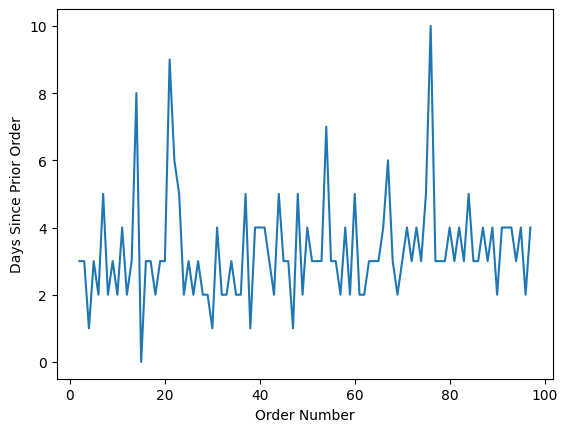

In [40]:
plt.plot(
    user_210['order_number'],
    user_210['days_since_prior_order']
)
plt.xlabel('Order Number')
plt.ylabel('Days Since Prior Order')

-- there is little to no pattern

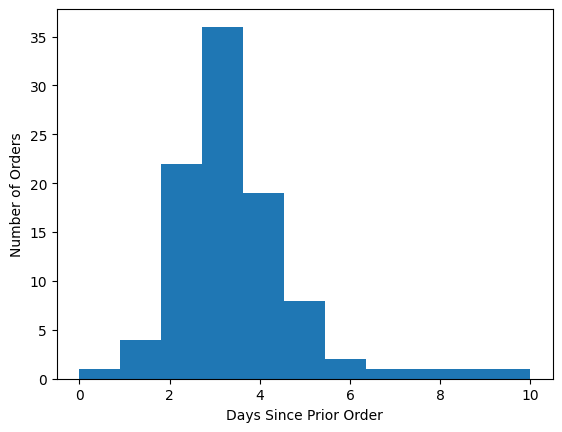

In [43]:
plt.hist(user_210['days_since_prior_order'], bins=11)
plt.xlabel('Days Since Prior Order')
plt.ylabel('Number of Orders')
plt.show()

In [45]:
# let's look at something more interesting -
# what happens when the user ordres on a traditional high volume day (sunday/monday)?
# how does that compare to the other 5 days
# look at days since prior in these two groups
user_210 = user_210.sort_values('order_number').copy()

user_210['days_until_next_order'] = (
    user_210['days_since_prior_order'].shift(-1)
)

In [47]:
import numpy as np

user_210['day_group'] = np.where(
    user_210['order_dow'].isin([0, 1]),
    'Sun/Mon',
    'Tue-Sat'
)

In [48]:
user_210.groupby('day_group')['days_until_next_order'].describe()

,count,mean,std,min,25%,50%,75%,max
day_group,,,,,,,,
Sun/Mon,33.0,3.575758,1.061553,2.0,3.0,3.0,4.0,6.0
Tue-Sat,63.0,3.174603,1.764705,0.0,2.0,3.0,4.0,10.0


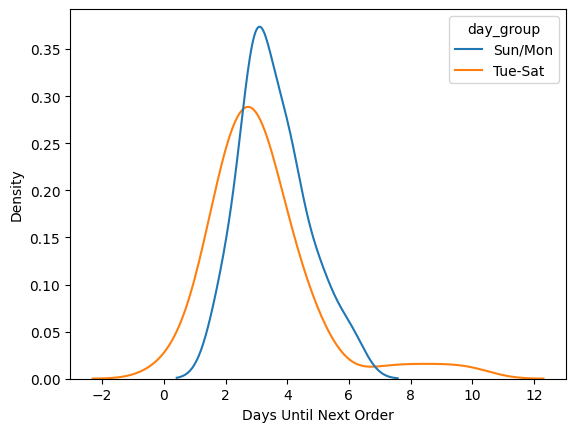

In [53]:
import seaborn as sns

sns.kdeplot(
    data=user_210,
    x='days_until_next_order',
    hue='day_group',
    common_norm=False
)

plt.xlabel('Days Until Next Order')
plt.show()